# SIC 2026 · Inteligencia Artificial
## Clase 3: Ustedes enseñan el Capítulo 5 (Machine Learning supervisado)

**Samsung Innovation Campus Chile 2026 · ONG Innovacien**

Hoy la clase la dan ustedes. El curso se divide en tres grupos y cada uno se hace cargo de una parte del **Capítulo 5: Machine Learning 1, aprendizaje supervisado**. Cada grupo prepara una explicación de los conceptos centrales y la muestra con **ejemplos prácticos creados por ustedes**, no copiados de las láminas.

**Presentación del Capítulo 5:** [abrir en Google Drive](https://drive.google.com/file/d/1pcJHh13Ra2yuhA-vyDja2Z-sAfXGO_y9/view?usp=drive_link)

| Grupo | Láminas | Tema |
|---|---|---|
| **Grupo 1** | 14 a 194 | Unidad 1: fundamentos de ML con scikit-learn, datos, preprocesamiento, optimización y métricas |
| **Grupo 2** | 195 a 314 | Unidades 2 y 3: regresión lineal y regresión logística |
| **Grupo 3** | 315 al final | Unidades 4 a 8: árbol de decisión, Naive Bayes, KNN, SVM y ensambles |

El Grupo 1 es el más grande porque su parte es la base de todo lo demás: si la clase no entiende bien `fit`, la división de datos o las métricas, el resto no se sostiene.

---
# Parte 0. Cómo funciona la clase

## Agenda

| Hora | Actividad |
|---|---|
| 18:00 a 18:15 | Explicación de la dinámica y formación de grupos |
| 18:15 a 19:15 | Preparación en grupos (salas separadas en Meet) |
| 19:15 a 20:15 | Presenta el **Grupo 1** |
| 20:15 a 20:25 | Pausa |
| 20:25 a 21:05 | Presenta el **Grupo 2** |
| 21:05 a 21:45 | Presenta el **Grupo 3** |
| 21:45 a 22:00 | Cierre y preguntas de repaso |

## Organización

Cada grupo se divide en **subgrupos de 2 o 3 personas**, uno por bloque de láminas. Cada subgrupo presenta **10 a 12 minutos**:

1. **Explicación (4 a 5 min):** los conceptos centrales con sus propias palabras. No lean las láminas.
2. **Ejemplo propio (4 a 5 min):** código que ustedes escribieron, ejecutado en vivo, con un dataset distinto al de las láminas cuando sea posible.
3. **Ejercicio para la clase (2 min):** un ejercicio corto que sus compañeros resuelven en este mismo notebook, con su celda de verificación.

## Qué tiene cada sección de este notebook

- **Láminas** que les corresponden y **conceptos que deben explicar** (es la lista mínima).
- **Preguntas que la clase debe poder responder** después de su presentación. Úsenlas para revisar si su explicación quedó completa.
- **Material de reserva:** notebooks de ejercicios y datos del capítulo que pueden usar como punto de partida.
- **Kit de inicio:** una celda que ya funciona, para que no partan de cero. Modifíquenla, amplíenla o reemplácenla.
- **Espacios para su explicación, su ejemplo y su ejercicio.**

## Qué se considera una buena presentación

| Criterio | Qué significa |
|---|---|
| Conceptos claros | Explican el porqué, no solo el cómo. Usan ejemplos cotidianos. |
| Ejemplo propio | El código es de ustedes, funciona y muestra el concepto. |
| Ejercicio para la clase | Es corto, se puede resolver en 2 minutos y tiene verificación. |
| Tiempo | Respetan los 10 a 12 minutos del subgrupo. |

**Al terminar**, guarden el notebook de su grupo en el repositorio con *Archivo > Guardar una copia en GitHub*, en la carpeta `ejercicios_estudiantes`, con el nombre `clase03_grupo1A_apellidos.ipynb` (cambiando el subgrupo).

## Preparación del entorno

Ejecuten esta celda. Importa las librerías, define la función `revisar` (la misma de la Clase 2) y una función `cargar_csv` para los datos de reserva del capítulo.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

def revisar(condicion, mensaje_ok="Correcto.", mensaje_error="Todavía no. Revisa tu respuesta."):
    """Imprime si un ejercicio está bien resuelto."""
    try:
        print(mensaje_ok if condicion() else mensaje_error)
    except Exception:
        print(mensaje_error)

URL_DATOS = "https://raw.githubusercontent.com/davidlealo/sic_ia_2026/main/datos/cap05/"

def cargar_csv(nombre):
    """Carga un CSV de reserva del capítulo 5: primero desde el repositorio y, si no está, desde los archivos subidos a Colab."""
    try:
        return pd.read_csv(URL_DATOS + nombre)
    except Exception:
        try:
            return pd.read_csv(nombre)
        except FileNotFoundError:
            print(f"No encontré {nombre}. Súbelo con el ícono de carpeta de la izquierda o con:")
            print("from google.colab import files; files.upload()")

print("Listo.")

Listo.


**Datos de reserva del capítulo** (también están en la carpeta del curso en Drive):

| Archivo | Contenido | Sirve para |
|---|---|---|
| `data_Iris.csv` | Medidas de flores iris y su especie | Clasificación, EDA (Grupo 1) |
| `data_galton.csv` | Estatura de padres e hijos | Regresión lineal simple |
| `TV_Sales.csv` | Ventas de televisores según precio, ingreso y ubicación | Regresión múltiple, diagnóstico, árboles |
| `data_studentlist.csv` | Estudiantes con género, edad, estatura y peso | Variables dummy e interacción |
| `data_mtcars.csv` | Características de 32 autos | Ridge y Lasso |
| `data_titanic.csv` | Titanic original con nombres, cabina y faltantes | Faltantes, preprocesamiento, KNN |
| `data_titanic_2.csv` | Titanic ya preprocesado | Árboles, KNN |

También pueden usar los datasets incluidos en librerías, que no requieren descargar nada: en scikit-learn `load_wine`, `load_breast_cancer`, `load_diabetes`, `load_digits`, `make_moons`; en seaborn `penguins`, `tips`, `mpg`, `diamonds`. **Usar un dataset distinto al de las láminas es la mejor forma de demostrar que entendieron.**

---
# Grupo 1. Fundamentos de machine learning con scikit-learn (láminas 14 a 194)

Esta es la Unidad 1 del capítulo y la base de todo lo que viene. Se divide en cuatro subgrupos:

| Subgrupo | Láminas | Tema |
|---|---|---|
| 1A | 14 a 47 | Parámetros e hiperparámetros, la API de scikit-learn |
| 1B | 48 a 112 | División de datos, sobreajuste, validación cruzada y preprocesamiento |
| 1C | 113 a 171 | Regularización y cómo encontrar el mejor modelo (caso iris) |
| 1D | 172 a 194 | Métricas de evaluación de clasificación |

## 1A · Parámetros, hiperparámetros y la API de scikit-learn

**Láminas:** 14 a 47

**Conceptos que deben explicar:**

- Diferencia entre **parámetro** (lo aprende el modelo) e **hiperparámetro** (lo elige la persona).
- Qué es un **estimador**, un **clasificador** y un **regresor** en scikit-learn.
- Los tres métodos centrales: `fit`, `predict` y `transform`, y el atajo `fit_transform`.
- El flujo básico: cargar datos, dividir, crear el estimador, entrenar, predecir y evaluar.
- Principales módulos de scikit-learn (`datasets`, `model_selection`, `preprocessing`, `metrics`, etc.).

**Preguntas que la clase debe poder responder después de su presentación:**

1. En una regresión lineal, ¿la pendiente es un parámetro o un hiperparámetro? ¿Y el número de vecinos en KNN?
2. ¿Qué hace `fit` en un modelo y qué hace en un `StandardScaler`?
3. ¿Por qué el escalador se ajusta con los datos de entrenamiento y no con los de prueba?

**Material de reserva:** Láminas 21 a 45 y la sección 1.2 de `SIC_AI_Ch05_Unit01.ipynb` (carpeta *Data and IPYNB Files / Chapter 5*).

### Kit de inicio

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X, y = load_wine(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Un transformador: fit aprende media y desviación; transform las aplica
escalador = StandardScaler().fit(X_tr)
X_tr_esc, X_te_esc = escalador.transform(X_tr), escalador.transform(X_te)
print("Media aprendida (primeras 3 columnas):", escalador.mean_[:3].round(2))

# Un estimador: n_neighbors es un hiperparámetro que elegimos nosotros
knn = KNeighborsClassifier(n_neighbors=5).fit(X_tr_esc, y_tr)
print("Exactitud en prueba:", round(knn.score(X_te_esc, y_te), 3))

Media aprendida (primeras 3 columnas): [12.96  2.29  2.36]
Exactitud en prueba: 0.944


### Ideas para su ejemplo propio

- Muestren los parámetros que aprende una `LinearRegression` (`coef_`, `intercept_`) y contrástenlos con un hiperparámetro.
- Comparen la exactitud de KNN **con y sin** escalar los datos para mostrar por qué importa `transform`.
- Usen `penguins` o `load_wine` en vez de iris.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 1A
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (1A)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 1A: sus compañeros escriben aquí su respuesta
respuesta_1a = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 1A (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_1a == valor_correcto)

## 1B · División de datos, sobreajuste, validación cruzada y preprocesamiento

**Láminas:** 48 a 112

**Conceptos que deben explicar:**

- Por qué se dividen los datos en **entrenamiento y prueba**, y qué es la **generalización**.
- **Sobreajuste** y su relación con la flexibilidad del modelo.
- **Validación cruzada**: k-fold y dejar uno fuera (LOO).
- **Valores faltantes**: detectarlos, eliminar filas o columnas, e **imputar** con `SimpleImputer`.
- **Datos categóricos**: ordinales y nominales, codificación de etiquetas y **one-hot** (`get_dummies`, `OneHotEncoder`).
- **Escalado** de características: normalización (MinMax) y estandarización.

**Preguntas que la clase debe poder responder después de su presentación:**

1. ¿Por qué evaluar con los mismos datos de entrenamiento da una nota engañosa?
2. ¿Qué ventaja tiene la validación cruzada de 5 pliegues frente a una sola división?
3. ¿Cuándo conviene codificar una variable con números enteros y cuándo con one-hot?
4. ¿Qué diferencia hay entre `MinMaxScaler` y `StandardScaler`?

**Material de reserva:** Sección 1.4 de `SIC_AI_Ch05_Unit01.ipynb`; `data_titanic.csv` tiene faltantes reales para practicar.

### Kit de inicio

In [ ]:
from sklearn.model_selection import cross_val_score, KFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier

pin = sns.load_dataset("penguins")
print("Faltantes por columna:\n", pin.isna().sum())

# Imputar numéricas con la mediana
num = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X_num = SimpleImputer(strategy="median").fit_transform(pin[num])

# One-hot para la isla (nominal)
X_isla = OneHotEncoder(sparse_output=False).fit_transform(pin[["island"]])
print("Categorías de isla:", OneHotEncoder().fit(pin[["island"]]).categories_)

# Escalado: misma columna con dos escaladores
masa = pin[["body_mass_g"]].dropna()
print("MinMax:", MinMaxScaler().fit_transform(masa)[:3].ravel().round(2),
      "| Estándar:", StandardScaler().fit_transform(masa)[:3].ravel().round(2))

# Validación cruzada de 5 pliegues
X = np.hstack([X_num, X_isla]); y = pin["species"]
puntajes = cross_val_score(DecisionTreeClassifier(random_state=0), X, y, cv=KFold(5, shuffle=True, random_state=0))
print("Exactitud por pliegue:", puntajes.round(3), "| promedio:", puntajes.mean().round(3))

### Ideas para su ejemplo propio

- Comparen tres estrategias de faltantes en `data_titanic.csv` (eliminar filas, mediana global, mediana por grupo) y su efecto en la exactitud.
- Muestren cómo cambia la exactitud de un árbol al variar `max_depth` en entrenamiento y en prueba (sobreajuste).
- Muestren que la nota de una sola división cambia según `random_state`, y que la validación cruzada la estabiliza.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 1B
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (1B)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 1B: sus compañeros escriben aquí su respuesta
respuesta_1b = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 1B (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_1b == valor_correcto)

## 1C · Regularización y búsqueda del mejor modelo

**Láminas:** 113 a 171

**Conceptos que deben explicar:**

- **Compensación sesgo-varianza** y cómo la **regularización** limita la complejidad del modelo.
- Diferencia entre **Ridge** (L2), **Lasso** (L1) y **Elastic Net**.
- El proceso completo con el caso **iris**: entender los datos, EDA, correlaciones, proporción de clases.
- **Selección de algoritmo** y estrategia de generalización: validación cruzada y **validación estratificada**.
- **Curva de aprendizaje**: qué dice sobre si conviene conseguir más datos.
- **Búsqueda de hiperparámetros** con `GridSearchCV`.

**Preguntas que la clase debe poder responder después de su presentación:**

1. ¿Por qué Lasso puede dejar coeficientes exactamente en cero y Ridge no?
2. ¿Qué indica una curva de aprendizaje donde entrenamiento y validación siguen separados?
3. Si `GridSearchCV` prueba 3 valores de un hiperparámetro y 4 de otro con 5 pliegues, ¿cuántos modelos entrena?

**Material de reserva:** Sección 1.5 de `SIC_AI_Ch05_Unit01.ipynb` y `data_Iris.csv`; `ex_0306.ipynb` con `data_mtcars.csv` para Ridge y Lasso.

### Kit de inicio

In [ ]:
from sklearn.datasets import load_diabetes, load_wine
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV, learning_curve, StratifiedKFold
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Regularización: cuántos coeficientes quedan en cero al aumentar alpha
Xd, yd = load_diabetes(return_X_y=True)
for a in [0.01, 0.1, 1]:
    print(f"alpha={a}: Ridge ceros={np.sum(Ridge(alpha=a).fit(Xd, yd).coef_ == 0)}, "
          f"Lasso ceros={np.sum(Lasso(alpha=a).fit(Xd, yd).coef_ == 0)}")

# Búsqueda de hiperparámetros con validación estratificada
Xw, yw = load_wine(return_X_y=True)
grilla = GridSearchCV(make_pipeline(StandardScaler(), SVC()),
                      {"svc__C": [0.1, 1, 10], "svc__gamma": ["scale", 0.1, 0.01, 0.001]},
                      cv=StratifiedKFold(5, shuffle=True, random_state=0))
grilla.fit(Xw, yw)
print("Mejores hiperparámetros:", grilla.best_params_, "| exactitud CV:", round(grilla.best_score_, 3))

# Curva de aprendizaje
tam, tr, va = learning_curve(grilla.best_estimator_, Xw, yw, cv=5, train_sizes=np.linspace(0.2, 1, 5))
plt.plot(tam, tr.mean(axis=1), marker="o", label="Entrenamiento")
plt.plot(tam, va.mean(axis=1), marker="o", label="Validación")
plt.xlabel("Ejemplos de entrenamiento"); plt.ylabel("Exactitud"); plt.legend(); plt.title("Curva de aprendizaje"); plt.show()

### Ideas para su ejemplo propio

- Grafiquen cómo se encogen los coeficientes de Ridge y Lasso al aumentar `alpha` (camino de regularización).
- Repliquen el proceso de iris con otro dataset: EDA, mapa de calor de correlaciones, proporción de clases, comparación de algoritmos con validación cruzada.
- Muestren qué pasa si no se estratifica cuando una clase es poco frecuente.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 1C
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (1C)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 1C: sus compañeros escriben aquí su respuesta
respuesta_1c = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 1C (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_1c == valor_correcto)

## 1D · Métricas de evaluación de clasificación

**Láminas:** 172 a 194

**Conceptos que deben explicar:**

- **Matriz de confusión**: verdaderos y falsos positivos y negativos, y su versión multiclase.
- **Precision, recall, fall-out y F1**: qué mide cada una y cuándo importa más.
- **Exactitud** y por qué no basta cuando las clases están desbalanceadas.
- `classification_report`.
- **Curva ROC** y **AUC**.
- Qué hacer si el rendimiento es malo: volver a pasos anteriores.

**Preguntas que la clase debe poder responder después de su presentación:**

1. En un test de una enfermedad grave, ¿qué es peor: un falso positivo o un falso negativo? ¿Qué métrica priorizarían?
2. Un modelo acierta 95% en un dataset donde 95% de los casos son negativos. ¿Es un buen modelo?
3. ¿Qué significa un AUC de 0,5?

**Material de reserva:** Láminas 172 a 194 y el final de la sección 1.5 de `SIC_AI_Ch05_Unit01.ipynb`.

### Kit de inicio

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score,
                             accuracy_score, classification_report, RocCurveDisplay, roc_auc_score)

Xb, yb = load_breast_cancer(return_X_y=True)   # 1 = benigno, 0 = maligno
X_tr, X_te, y_tr, y_te = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)
modelo = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
pred = modelo.predict(X_te)

print("Matriz de confusión:\n", confusion_matrix(y_te, pred))
print(f"Exactitud {accuracy_score(y_te, pred):.3f} | Precision {precision_score(y_te, pred):.3f} | "
      f"Recall {recall_score(y_te, pred):.3f} | F1 {f1_score(y_te, pred):.3f}")
print(classification_report(y_te, pred, target_names=["maligno", "benigno"]))

RocCurveDisplay.from_estimator(modelo, X_te, y_te)
plt.plot([0, 1], [0, 1], "--", color="gray"); plt.title(f"Curva ROC, AUC = {roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1]):.3f}"); plt.show()

### Ideas para su ejemplo propio

- Construyan un caso desbalanceado (por ejemplo, 95% de una clase) y muestren que un modelo que siempre predice la mayoría tiene buena exactitud pero recall cero.
- Calculen precision y recall **a mano** desde la matriz de confusión y compárenlos con scikit-learn.
- Usen un ejemplo cotidiano para explicar precision y recall: filtro de spam, detector de fraude, alarma de incendio.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 1D
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (1D)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 1D: sus compañeros escriben aquí su respuesta
respuesta_1d = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 1D (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_1d == valor_correcto)

---
# Grupo 2. Regresión lineal y regresión logística (láminas 195 a 314)

Unidades 2 y 3 del capítulo. Se divide en tres subgrupos:

| Subgrupo | Láminas | Tema |
|---|---|---|
| 2A | 195 a 237 | Errores de sesgo y varianza, regresión lineal y mínimos cuadrados |
| 2B | 238 a 266 | Diagnóstico de la regresión y otros tipos de regresión |
| 2C | 267 a 314 | Regresión logística y sus métricas |

**Coordinación:** el subgrupo 1D explica las métricas en general. El 2C se enfoca en lo propio de la regresión logística: probabilidades, punto de corte, sensibilidad, especificidad y ROC al mover el corte.

## 2A · Sesgo, varianza y regresión lineal

**Láminas:** 195 a 237

**Conceptos que deben explicar:**

- Tipos de error: **sesgo** (subajuste) y **varianza** (sobreajuste), y el error total.
- Qué es la **regresión lineal**, sus supuestos y su origen (Galton).
- El modelo lineal: variables explicativas, **coeficientes** e intercepto, y cómo **interpretarlos**.
- **Mínimos cuadrados ordinarios (OLS)**: qué minimiza.
- Entrenamiento y predicción, métricas de error (MSE, RMSE, MAE).
- **Variables categóricas** en regresión: dummies e interacción.

**Preguntas que la clase debe poder responder después de su presentación:**

1. Si el coeficiente de "metros cuadrados" en un modelo de precios es 1,5 millones, ¿cómo se interpreta?
2. ¿Qué minimiza exactamente el método de mínimos cuadrados?
3. ¿Qué cambia en el modelo al agregar una variable dummy y qué cambia al agregar una interacción?

**Material de reserva:** `ex_0301.ipynb` (Galton), `ex_0304.ipynb` (intervalo de confianza), `ex_0305.ipynb` (dummies e interacción, `data_studentlist.csv`).

### Kit de inicio

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

autos = sns.load_dataset("mpg").dropna()
X = autos[["weight"]]; y = autos["mpg"]   # rendimiento (millas por galón) según el peso
lr = LinearRegression().fit(X, y)
print(f"Intercepto: {lr.intercept_:.2f} | Pendiente: {lr.coef_[0]:.4f}")
print(f"Por cada 1000 libras más, el rendimiento cambia en {lr.coef_[0] * 1000:.2f} mpg")

# OLS "a mano" con álgebra lineal: beta = (X'X)^-1 X'y
Xm = np.column_stack([np.ones(len(X)), X])
beta = np.linalg.inv(Xm.T @ Xm) @ Xm.T @ y
print("OLS a mano:", beta.round(4))

pred = lr.predict(X)
print(f"RMSE: {mean_squared_error(y, pred) ** 0.5:.2f} | MAE: {mean_absolute_error(y, pred):.2f}")
plt.scatter(X, y, alpha=0.4); plt.plot(X.sort_values("weight"), lr.predict(X.sort_values("weight")), color="red")
plt.xlabel("Peso"); plt.ylabel("mpg"); plt.title("Regresión lineal simple"); plt.show()

### Ideas para su ejemplo propio

- Expliquen el origen del nombre "regresión" con `data_galton.csv`: los hijos de padres muy altos tienden a ser menos altos que sus padres.
- Agreguen al modelo de `mpg` una dummy de origen del auto (`origin`) y muestren cómo cambia el intercepto.
- Muestren sesgo y varianza ajustando un polinomio de grado 1, 3 y 15 a los mismos datos.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 2A
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (2A)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 2A: sus compañeros escriben aquí su respuesta
respuesta_2a = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 2A (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_2a == valor_correcto)

## 2B · Diagnóstico de la regresión y otras regresiones

**Láminas:** 238 a 266

**Conceptos que deben explicar:**

- Métricas de error y **coeficiente de determinación R²** (y R² ajustado).
- **Prueba F** de significancia global y **prueba t** de cada coeficiente.
- **Multicolinealidad** y el **factor de inflación de varianza (VIF)**.
- **Criterios de información AIC y BIC** para comparar modelos.
- **Análisis de residuos** y de **apalancamiento** (leverage).
- Otras regresiones: **Ridge, Lasso, polinomial y Poisson**.

**Preguntas que la clase debe poder responder después de su presentación:**

1. Un coeficiente tiene un valor p de 0,40. ¿Qué significa y qué harían con esa variable?
2. ¿Qué problema detecta un VIF de 15?
3. Entre dos modelos, uno con AIC 1416 y otro con AIC 1402, ¿cuál prefieren y por qué?
4. ¿Qué patrón en el gráfico de residuos indica que el modelo lineal no es adecuado?

**Material de reserva:** `ex_0302.ipynb` y `ex_0303.ipynb` (diagnóstico con `TV_Sales.csv` y StatsModels), `ex_0306.ipynb` (Ridge y Lasso con `data_mtcars.csv`).

### Kit de inicio

In [ ]:
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

autos = sns.load_dataset("mpg").dropna()
modelo = smf.ols("mpg ~ weight + horsepower + displacement + acceleration", data=autos).fit()
print(modelo.summary().tables[1])
print(f"R²: {modelo.rsquared:.3f} | R² ajustado: {modelo.rsquared_adj:.3f} | AIC: {modelo.aic:.1f} | p de F: {modelo.f_pvalue:.2e}")

# VIF de cada variable explicativa
Xv = autos[["weight", "horsepower", "displacement", "acceleration"]].assign(const=1)
print("VIF:", {c: round(variance_inflation_factor(Xv.values, i), 1) for i, c in enumerate(Xv.columns[:-1])})

# Residuos frente a valores ajustados
plt.scatter(modelo.fittedvalues, modelo.resid, alpha=0.4); plt.axhline(0, color="red")
plt.xlabel("Valores ajustados"); plt.ylabel("Residuos"); plt.title("Análisis de residuos"); plt.show()

# Regresión polinomial de grado 2
poli = make_pipeline(PolynomialFeatures(2), LinearRegression()).fit(autos[["horsepower"]], autos["mpg"])
print("R² polinomial (horsepower):", round(poli.score(autos[["horsepower"]], autos["mpg"]), 3))

### Ideas para su ejemplo propio

- Partan con todas las variables de `TV_Sales.csv`, eliminen una a una las no significativas y muestren cómo cambian R² ajustado y AIC.
- Muestren el patrón curvo de los residuos en `mpg ~ horsepower` y cómo desaparece con un término cuadrático.
- Comparen Ridge y Lasso en `data_mtcars.csv`: qué variables descarta Lasso.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 2B
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (2B)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 2B: sus compañeros escriben aquí su respuesta
respuesta_2b = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 2B (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_2b == valor_correcto)

## 2C · Regresión logística y sus métricas

**Láminas:** 267 a 314

**Conceptos que deben explicar:**

- Cómo elegir un algoritmo según el tipo de variable objetivo; tipos de algoritmos de clasificación.
- **Regresión logística**: odds, **logit** y **función sigmoide**.
- Entrenamiento por **descenso de gradiente**: la idea de minimizar la pérdida paso a paso.
- **Punto de corte** (threshold) y cómo cambia las predicciones.
- Matriz de confusión con **sensibilidad, especificidad y precisión**.
- **Curva ROC** al mover el corte e interpretación con el **teorema de Bayes**.

**Preguntas que la clase debe poder responder después de su presentación:**

1. Si un modelo entrega probabilidad 0,7, ¿qué predice con corte 0,5 y con corte 0,8?
2. ¿Por qué la regresión lineal no sirve para predecir una probabilidad?
3. Al bajar el punto de corte, ¿qué pasa con la sensibilidad y con la especificidad?

**Material de reserva:** `ex_0307.ipynb` (regresión logística, corte y ROC con `load_breast_cancer`).

### Kit de inicio

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# La función sigmoide convierte cualquier número en una probabilidad
z = np.linspace(-8, 8, 200)
plt.plot(z, 1 / (1 + np.exp(-z))); plt.axhline(0.5, ls="--", color="gray")
plt.title("Función sigmoide"); plt.xlabel("Combinación lineal z"); plt.ylabel("Probabilidad"); plt.show()

Xb, yb = load_breast_cancer(return_X_y=True)
X_tr, X_te, y_tr, y_te = train_test_split(Xb, yb, test_size=0.3, random_state=0, stratify=yb)
modelo = LogisticRegression(max_iter=5000).fit(X_tr, y_tr)
prob = modelo.predict_proba(X_te)[:, 1]

# Efecto del punto de corte en sensibilidad y especificidad
for corte in [0.3, 0.5, 0.7, 0.9]:
    tn, fp, fn, tp = confusion_matrix(y_te, (prob >= corte).astype(int)).ravel()
    print(f"Corte {corte}: sensibilidad {tp / (tp + fn):.3f} | especificidad {tn / (tn + fp):.3f}")

### Ideas para su ejemplo propio

- Implementen el descenso de gradiente con NumPy para un solo coeficiente y muestren cómo baja la pérdida en cada iteración.
- Usen `data_titanic_2.csv` o `penguins` (dos especies) y elijan el punto de corte según un objetivo explícito.
- Expliquen con números el ejemplo de Bayes: de 100 personas, 6 enfermas, un test con sensibilidad y especificidad dadas.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 2C
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (2C)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 2C: sus compañeros escriben aquí su respuesta
respuesta_2c = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 2C (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_2c == valor_correcto)

---
# Grupo 3. Árboles, Naive Bayes, KNN, SVM y ensambles (lámina 315 al final)

Unidades 4 a 8 del capítulo. Se divide en tres subgrupos:

| Subgrupo | Láminas | Tema |
|---|---|---|
| 3A | 315 a 340 | Árbol de decisión |
| 3B | 341 a 377 | Naive Bayes, KNN y SVM |
| 3C | 378 al final | Algoritmos de conjunto: votación, bagging, random forest y boosting |

La lámina 315 corresponde al ejercicio `ex_0307` de regresión logística, que trabaja el subgrupo 2C. El Grupo 3 parte con los árboles.

**Idea para cerrar el grupo:** comparen todos los algoritmos sobre un mismo dataset con validación cruzada. Es la mejor forma de mostrar que no existe un algoritmo que siempre gane.

## 3A · Árbol de decisión

**Láminas:** 315 a 340

**Conceptos que deben explicar:**

- Qué es un árbol y sus partes: **nodo, rama, hoja y profundidad**.
- Cómo se construye: **división recursiva** y criterio de división.
- Medidas de **impureza**: **índice de Gini** y **entropía**.
- **Criterios de parada** y el problema del **sobreajuste**; poda.
- **Árbol de clasificación** y **árbol de regresión**.
- Hiperparámetros principales en scikit-learn (`max_depth`, `min_samples_split`, `min_samples_leaf`, `criterion`).

**Preguntas que la clase debe poder responder después de su presentación:**

1. Un nodo tiene 50% de cada clase. ¿Cuál es su índice de Gini? ¿Y si tiene 100% de una clase?
2. ¿Por qué un árbol sin límite de profundidad sobreajusta?
3. ¿Qué predice una hoja en un árbol de regresión?

**Material de reserva:** `ex_0308.ipynb` (clasificación con `data_titanic_2.csv` y regresión con `TV_Sales.csv`).

### Kit de inicio

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

def gini(proporciones):
    p = np.array(proporciones)
    return 1 - np.sum(p ** 2)

def entropia(proporciones):
    p = np.array([x for x in proporciones if x > 0])
    return -np.sum(p * np.log2(p))

print("Gini 50/50:", gini([0.5, 0.5]), "| Gini 100/0:", gini([1, 0]))
print("Entropía 4 clases iguales:", entropia([0.25] * 4))

pin = sns.load_dataset("penguins").dropna()
X = pin[["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]; y = pin["species"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
arbol = DecisionTreeClassifier(max_depth=2, criterion="gini", random_state=0).fit(X_tr, y_tr)
print("Exactitud en prueba:", round(arbol.score(X_te, y_te), 3))
plt.figure(figsize=(12, 5)); plot_tree(arbol, feature_names=X.columns, class_names=arbol.classes_, filled=True, rounded=True); plt.show()

### Ideas para su ejemplo propio

- Calculen a mano el Gini de la raíz y de sus dos hijos en el árbol de arriba, y muestren cuánto baja la impureza.
- Optimicen `max_depth` y `min_samples_leaf` con `GridSearchCV` en `data_titanic_2.csv`.
- Ajusten un `DecisionTreeRegressor` a `TV_Sales.csv` y grafiquen la predicción "en escalones".

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 3A
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (3A)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 3A: sus compañeros escriben aquí su respuesta
respuesta_3a = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 3A (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_3a == valor_correcto)

## 3B · Naive Bayes, KNN y SVM

**Láminas:** 341 a 377

**Conceptos que deben explicar:**

- **Teorema de Bayes** y por qué Naive Bayes es "ingenuo" (supone independencia).
- **Naive Bayes gaussiano** y el ejemplo de probabilidad condicional de las láminas.
- **KNN**: clasificar según los k vecinos más cercanos, efecto de k (pequeño sobreajusta, grande subajusta) y la importancia de escalar.
- **SVM**: hiperplano, **margen**, **vectores de soporte** y el parámetro **C**.
- **Kernels**: llevar los datos a una dimensión mayor para separarlos (lineal, polinomial, RBF).

**Preguntas que la clase debe poder responder después de su presentación:**

1. ¿Por qué KNN necesita que las variables estén en la misma escala?
2. ¿Qué pasa con KNN si k = 1? ¿Y si k es igual al total de datos?
3. ¿Para qué sirve un kernel en SVM? Den un ejemplo de datos que una línea recta no puede separar.

**Material de reserva:** `ex_0309.ipynb` (Naive Bayes con iris), `ex_0310.ipynb` (KNN con Titanic), `ex_0311.ipynb` (SVM y kernels con iris).

### Kit de inicio

Naive Bayes: 0.966
KNN k=1: sin escalar 0.725 | escalado 0.950
KNN k=5: sin escalar 0.691 | escalado 0.949
KNN k=15: sin escalar 0.714 | escalado 0.955
KNN k=50: sin escalar 0.725 | escalado 0.961


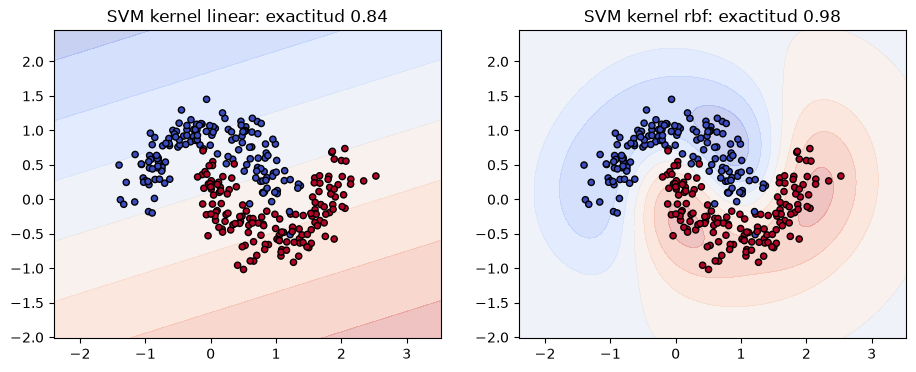

In [3]:
from sklearn.datasets import load_wine, make_moons
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.model_selection import cross_val_score

Xw, yw = load_wine(return_X_y=True)
print("Naive Bayes:", cross_val_score(GaussianNB(), Xw, yw, cv=5).mean().round(3))
for k in [1, 5, 15, 50]:
    sin = cross_val_score(KNeighborsClassifier(k), Xw, yw, cv=5).mean()
    con = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(k)), Xw, yw, cv=5).mean()
    print(f"KNN k={k}: sin escalar {sin:.3f} | escalado {con:.3f}")

# SVM: kernel lineal frente a RBF en datos con forma de media luna
Xm, ym = make_moons(n_samples=300, noise=0.2, random_state=0)
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, kernel in zip(ejes, ["linear", "rbf"]):
    svm = SVC(kernel=kernel, C=1).fit(Xm, ym)
    DecisionBoundaryDisplay.from_estimator(svm, Xm, ax=eje, alpha=0.3, cmap="coolwarm")
    eje.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", edgecolor="k", s=20)
    eje.set_title(f"SVM kernel {kernel}: exactitud {svm.score(Xm, ym):.2f}")
plt.show()

### Ideas para su ejemplo propio

- Grafiquen la exactitud de KNN para k de 1 a 50 en entrenamiento y validación para encontrar el mejor k.
- Muestren el efecto de C y de `gamma` en la frontera de la SVM RBF con `make_moons`.
- Resuelvan el ejemplo de Bayes de las láminas (clientes que compran o miran) con una tabla en pandas.

### Su explicación

#### Naive Bayes

Es un clasificador probabilístico basado en el teorema de Bayes, con una suposición simplificadora que le da el nombre de *ingenuo*.

Teorema de Bayes

Parte de la definición de probabilidad condicional. La probabilidad que ocurran A y B juntos se puede escribir de dos formas:

$$ P(A \cap B) = P(A|B)\,P(B) = P(B|A)\,P(A)$$

Igualando y despejando se obtiene el teorema:

$$P(A|B) = \frac{P(B|A)\,P(A)}{P(B)}$$

Es decir, la probabilidad que suceda A dado B, $P(A|B)$, es el producto de la verosimilitud $P(B|A)$ por la probabilidad previa $P(A)$, dividido por la probabilidad de que ocurra B, $P(B)$.

Otra forma de interpretarlo es como una manera de actualizar una creencia con evidencia nueva:

- $P(A)$: creencia previa (a priori), antes de ver la evidencia.
- $P(B|A)$: verosimilitud, qué tan esperable es la evidencia si A es cierto.
- $P(A|B)$: creencia actualizada (a posteriori).
- $P(B)$: normalizador o evidencia, para que las probabilidades de todas las clases sumen 1.

Ingenuidad

Estimar directamente la verosimilidad es muy difícil, sobre todo a medida que incorporamos más caracteristicas observadas $B=x_1, \dots, x_n$. Naive Bayes asume que las **características son condicionalmente independientes dada la clase**:

$$P(x_1, \dots, x_n \mid C) = \prod_{i=1}^{n} P(x_i \mid C)$$

Esto reduce enormemente el número de parámetros a estimar. En general, la suposición no es cierta en realidad; por ejemplo, en un correo las palabras "oferta" y "gratis" tienden a aparecer juntas. Aun así, el clasificador suele funcionar bien. La clase predicha es:

$$\hat{C} = \arg\max_C \; P(C)\prod_{i=1}^{n} P(x_i \mid C)$$

Naive Bayes Gaussiano

Cuando las características son continuas (por ejemplo, minutos dentro de una tienda), no se pueden contar frecuencias. Se asume que, dada la clase, cada característica sigue una **distribución normal**:

$$P(x_i|C) = \frac{1}{\sqrt{2\pi\sigma^2_{C,i}}}\text{exp}\left(-\frac{(x_i-\mu_{C,i})^2}{2\sigma^2_{C,i}}\right)$$

Entrenar consiste en estimar, para cada clase y característica, la media $\mu_{C,i}$ y la varianza $\sigma^2_{C,i}$, además del prior $P(C)$. Para clasificar se mantiene la regla ingenua de independencia entre las características.

Es importante recordar que $P(x_i|C)$ (la verosimilitud) es aquí una densidad, no una probabilidad; por eso puede ser mayor a 1, pero no afecta la comparación entre clases.

Ejemplo: Diferenciar los grupos de personas que "van de compras" y quienes "miran escaparates"

Primero, definimos las probabilidades a priori de cada clase:
- $P(\text{compra})$ = 0.2
- $P(\text{escaparate})$ = 0.8

Luego, establecemos la probabilidad condicional de que la persona inicie una conversación

| Tipo | Probabilidad de iniciar conversación | Probabilidad de no iniciarla |
|----------|--------------------------------------|--------------------------|
|compras   | 0.9                                  | 0.1                      |
|escaparate| 0.3                                  | 0.7                      |

Entonces si vemos que alguien **inicia una conversación**, ¿qué tan probable es que compre?

\begin{equation}
P(\text{compra}|\text{conversa}) = \frac{0.9 \cdot 0.2}{0.9 \cdot 0.2 + 0.3 \cdot 0.8} \approx 0.43
\end{equation}

y si **no conversa**

\begin{equation}
P(\text{compra}|\text{no conversa}) = \frac{0.1 \cdot 0.2}{0.1 \cdot 0.2 + 0.7 \cdot 0.8} \approx 0.03
\end{equation}

La creencia previa que una persona compre era 20%. Si la persona conversa, sube a 43%; si no conversa, baja a 3%. Este ejemplo ilustra la lógica bayesiana; la version gaussiana se aplica cuando la evidencia es una variable continua, como el tiempo en la tienda.


#### K-Nearest Neighbors

Consiste en un método de clasificación supervisado de Machine Learning, que se utiliza para darle valor, o clase, a un dato nuevo a partir de los k datos más parecidos

Si lo utilizamos en una clasificación, gana la clase que más se repite entre los k vecinos.
Si lo utilizamos en una regresión, el dato toma el valor promedio de lo k vecinos.

Lo "parecido" se calcula a partir de la distancia entre datos, normalmente euclidiana. **Los más cercanos, los más parecidos**

**La importancia del valor k**

El valor k representa la cantidad de vecinos que se utilizan para clasificar (o realizar la regresión) al dato. No hay fórmula para calcularlo, pero es importante comparar los resultados para escoger el más óptimo.

- Si k es muy pequeño el algoritmo se sobreajusta, es decir, se convierte en el valor más cercano aunque sea ruido.
- Si k es muy grande el algoritmo se generaliza, es decir, se convierte en el valor más repetido de todos los datos.

**La importancia de la escala**

|Persona|Edad|Sueldo|
|-------|----|-------|
|A      |25  |800.000|
|B      |60  |810.000|
|C      |26  |900.000|

¿A quién se parece más a A?
- Según la distancia es B, porque la distancia entre sueldos pesa mucho más.
- Si escalamos a valores similares, ambas personas se aproximan similar.

#### Support Vector Machines 

Un SVM busca la mejor frontera que separe dos clases, es decir, la que deje el mayor espacio libre entre ella y los puntos de ambas clases. 

**Ventajas**
* No es muy sensible a los valores atípicos.
* Tiene buen rendimiento.

**Desventajas**
* Entrenamiento relativamente lento. Funciona mal para grandes cantidades de datos.
* El kernel y el conjunto de hiperparámetros debe optimizarse cuidadosamente.
* No se obtiene mucha información.

**Hiperplano**: es la frontera de decisión. En 2D es una recta, en 3D es un plano y en más dimensiones es un hiperplano.

**Margen**: es la distancia entre el hiperplano y los puntos más cercanos de cada clase. Queda delimitado por dos hiperplanos paralelos al de decisión.

**Vectores de Soporte**: son los puntos que quedan justo en el borde del margen (o dentro de él, o mal clasificados si hay holgura). Ellos determinan el hiperplano.

**Parámetro C**: controla el compromiso entre un margen ancho y la penalización de los errores de entrenamiento. Se elige por validación cruzada.
- Si C es grande, se penalizan fuertemente los errores y el modelo se aproxima al *hard margin*, con tendencia al sobreajuste (*overfitting*).
- Si C es pequeño, el margen es más ancho y se toleran más puntos mal clasificados. con tendencia al subajuste (*underfitting*).

No siempre las clases son separables linealmente. Podemos llevar los datos a un espacio de mayor dimension donde la frontera sí sea un (hiper)plano.

Sin embargo, calcular explícitamente ese nuevo espacio es muy costoso. Lo que sí podemos hacer es el **truco del kernel**, que consiste en calcular directamente el producto punto entre los pares de puntos como si los datos estuvieran en esa dimensión extra, sin construirla realmente.

Como se ve en las imágenes, un caso de clasificación no lineal es aquel en que una categoría está rodeada por otra.

Mapeo efectivo a una dimensión superior mediante el producto interno de dos vetores $x_1$ y $x_2$: $K(x_1,x_2) = \phi(x_1) \cdot \phi(x_2)$

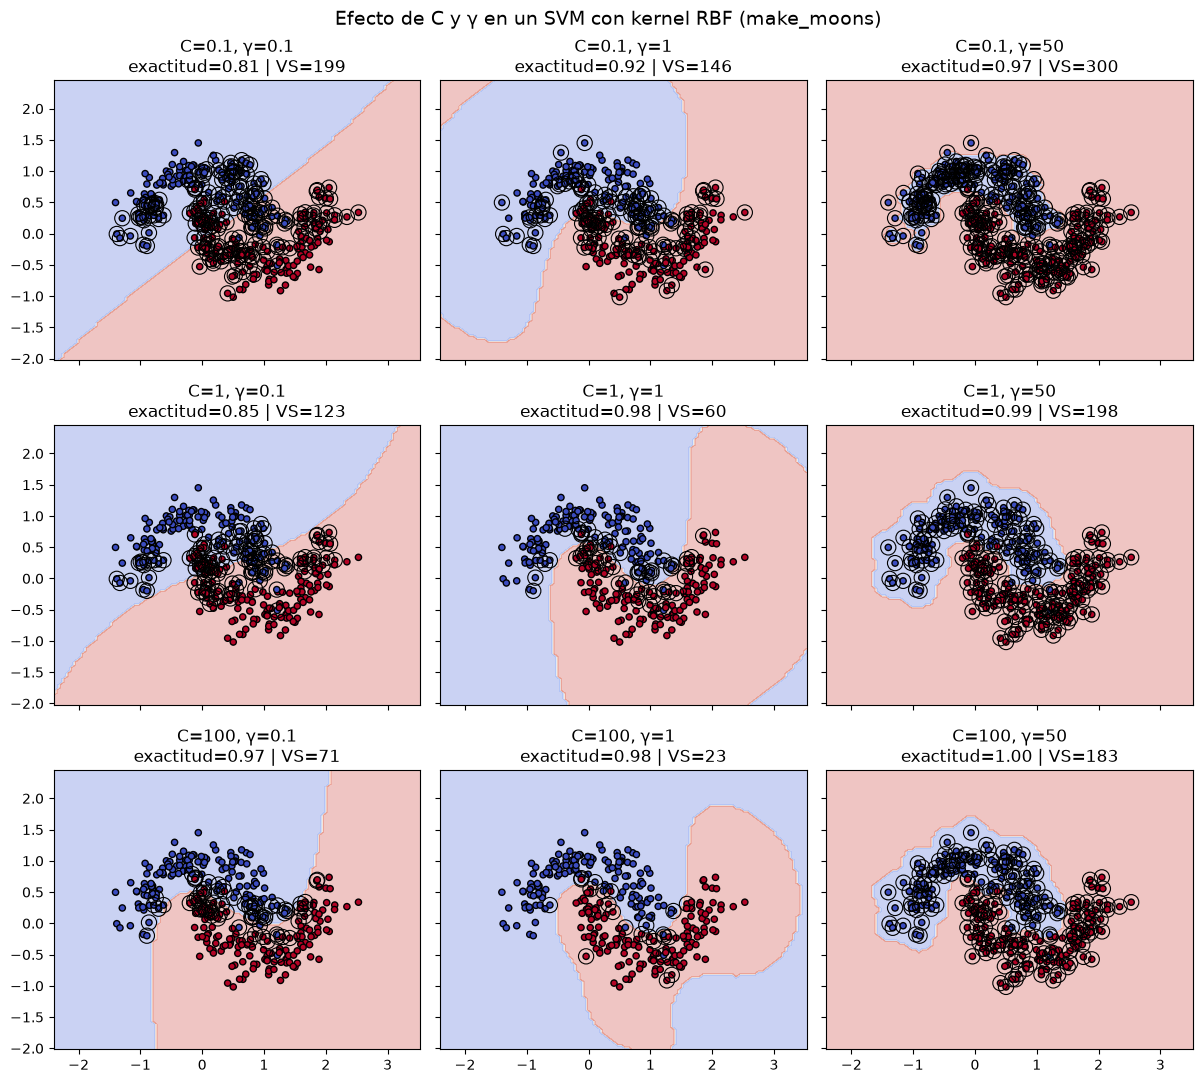

In [4]:
# Ejemplo propio del subgrupo 3B
# Efecto de C y de gamma en la frontera de la SVM RBF

# Creamos los datos para comparar como los hiperparámetros interactuan entre ellas.
Xm, ym = make_moons(n_samples=300, noise=0.2, random_state=0)

# Lista de hiperparámetros a probar
Cs = [0.1, 1, 100]
# C nos indica la tolerancia a la mala clasificación. Si es muy grande, la 
# tolerancia es pequeña y se tiene al sobreajuste. Si es muy pequeña, la 
# tolerancia es grande y tiende al subajuste.
gammas = [0.1, 1, 50]
# Gamma es que tan influyente es cada punto a la definición de la frontera.
# Si gamma es grande, la influencia es muy local y se tiende al sobreajuste.
# Si gamma es pequeño, la influencia es amplia y tiende a comportarse de manera lineal. 

# Grid de plot (filas para los distintos C y columnas para los distintos gammas)
fig, ejes = plt.subplots(len(Cs), len(gammas), figsize=(12, 11), sharex=True, sharey=True)

for i, C in enumerate(Cs):
    for j, gamma in enumerate(gammas):
        eje = ejes[i, j]
        svm = SVC(kernel="rbf", C=C, gamma=gamma).fit(Xm, ym)

        DecisionBoundaryDisplay.from_estimator(
            svm, Xm, ax=eje, alpha=0.3, cmap="coolwarm", response_method="predict"
        )
        eje.scatter(Xm[:, 0], Xm[:, 1], c=ym, cmap="coolwarm", edgecolor="k", s=20)

        # Vectores de soporte resaltados con un círculo grande
        eje.scatter(
            svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
            s=120, facecolors="none", edgecolors="k", linewidths=0.8,
        )
        eje.set_title(f"C={C}, γ={gamma}\nexactitud={svm.score(Xm, ym):.2f} | VS={len(svm.support_)}")

fig.suptitle("Efecto de C y γ en un SVM con kernel RBF (make_moons)", fontsize=14)
plt.tight_layout()
plt.show()

### Ejercicio para la clase (3B)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 3B: sus compañeros escriben aquí su respuesta
respuesta_3b = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 3B (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_3b == valor_correcto)

## 3C · Algoritmos de conjunto

**Láminas:** 378 al final

**Conceptos que deben explicar:**

- Idea del **aprendizaje en conjunto**: combinar modelos débiles para decidir mejor; **bootstrap**.
- **Votación** dura y blanda (`VotingClassifier`).
- **Bagging** y **random forest**: árboles con muestras y variables al azar; menor varianza.
- Diferencia entre bagging y votación.
- **Boosting**: modelos secuenciales que corrigen errores anteriores; **AdaBoost**, **Gradient Boosting**, XGBoost y LightGBM.
- Hiperparámetros principales (`n_estimators`, `max_features`, `learning_rate`).

**Preguntas que la clase debe poder responder después de su presentación:**

1. ¿Qué diferencia hay entre votación dura y blanda?
2. ¿Por qué un random forest sobreajusta menos que un solo árbol?
3. ¿En qué se diferencia la forma de entrenar de bagging y la de boosting?

**Material de reserva:** `ex_0312.ipynb` (comparación de árboles con `load_digits`), `ex_0313.ipynb` (votación), `ex_0314.ipynb` (bagging y boosting). XGBoost y LightGBM vienen instalados en Colab.

### Kit de inicio

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

Xb, yb = load_breast_cancer(return_X_y=True)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(5))
arbol = DecisionTreeClassifier(max_depth=4, random_state=0)

modelos = {
    "Árbol solo": arbol,
    "Votación blanda": VotingClassifier([("lr", logit), ("knn", knn), ("arbol", arbol)], voting="soft"),
    "Random forest": RandomForestClassifier(n_estimators=200, random_state=0),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, random_state=0),
    "Gradient boosting": GradientBoostingClassifier(random_state=0),
}
for nombre, m in modelos.items():
    print(f"{nombre:18s} exactitud CV: {cross_val_score(m, Xb, yb, cv=5).mean():.3f}")

### Ideas para su ejemplo propio

- Grafiquen la exactitud de un random forest al aumentar `n_estimators` de 1 a 300.
- Muestren la importancia de variables de un random forest y compárenla con la de un solo árbol.
- Comparen todos los algoritmos del capítulo sobre un mismo dataset en una sola tabla para cerrar la clase.

### Su explicación

*(Doble clic para escribir. Resuman aquí los conceptos con sus palabras; les sirve de guion.)*

In [ ]:
# Ejemplo propio del subgrupo 3C
# TU CÓDIGO AQUÍ

### Ejercicio para la clase (3C)

*(Escriban aquí el enunciado del ejercicio para sus compañeros.)*

In [ ]:
# Ejercicio 3C: sus compañeros escriben aquí su respuesta
respuesta_3c = None  # TU CÓDIGO AQUÍ

In [ ]:
# Verificación del ejercicio 3C (la escribe el subgrupo que presenta)
# Ejemplo: revisar(lambda: respuesta_3c == valor_correcto)

---
# Cierre: síntesis del capítulo

Completen esta tabla durante las presentaciones. Al final de la clase la revisamos entre todos.

| Algoritmo | ¿Clasificación, regresión o ambas? | Hiperparámetro principal | Necesita escalar | Una ventaja | Una desventaja |
|---|---|---|---|---|---|
| Regresión lineal | | | | | |
| Ridge / Lasso | | | | | |
| Regresión logística | | | | | |
| Árbol de decisión | | | | | |
| Naive Bayes | | | | | |
| KNN | | | | | |
| SVM | | | | | |
| Random forest | | | | | |
| Boosting | | | | | |

## Preguntas de repaso

1. ¿Por qué siempre evaluamos con datos que el modelo no vio durante el entrenamiento?
2. ¿Qué diferencia hay entre un parámetro y un hiperparámetro? Den un ejemplo de cada uno.
3. ¿Qué métrica usarían para un detector de fraude, donde los fraudes son el 1% de los casos?
4. ¿Qué algoritmos del capítulo necesitan escalar los datos y por qué?
5. Si tuvieran que elegir un solo algoritmo para empezar un proyecto nuevo de clasificación, ¿cuál elegirían y por qué?

**Recuerden** guardar el notebook en el repositorio, en la carpeta `ejercicios_estudiantes`.

Repositorio del curso: https://github.com/davidlealo/sic_ia_2026